# 2. Pembersihan data

Satuan ppm diubah ke µg/m³ (gas memakai berat molekul dan volume molar 24,45; partikulat dikali 1.000 karena tercatat dalam mg/m³). Baris saat alat tidak mengukur udara dikosongkan, baris SUSPECT disimpan bila nilainya masih di dalam rentang data VALID stasiun yang sama, nilai identik selama 24 jam atau lebih dianggap sensor macet, waktu dibulatkan ke jam terdekat, data 15 menit PLB-01 dirata-ratakan per jam, dan JMB-02 dikeluarkan. Jam yang kosong tidak diisi.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = "../data/raw/"
CLEAN = "../data/clean/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
POL = ["pm25", "pm10", "so2", "co", "o3", "no2"]
MET = ["temperature_c", "humidity_pct", "wind_speed_ms", "wind_direction_deg"]
DIKELUARKAN = ["JMB-02"]
AWAL, AKHIR = pd.Timestamp("2024-01-01 00:00"), pd.Timestamp("2026-10-14 23:00")
GRID = pd.date_range(AWAL, AKHIR, freq="h")
BM = {"so2": 64.07, "no2": 46.01, "o3": 48.00, "co": 28.01}
MIN_JAM_MACET = 24
FLAG_BUANG = ["CALIBRATING", "WARMUP", "MAINTENANCE", "MISSING", "PARSER_FAIL", "FATAL_ERR",
              "GARBAGE", "COMM_LOST", "CORRUPT", "SENSOR_DEAD"]

In [3]:
log, hasil, mentah_simpan = [], [], {}

In [4]:
for f in sorted(glob.glob(RAW + "*_AQMS.csv")):
    kode = re.search(r"([A-Z0-9]+-\d+)_", f).group(1)
    if kode in DIKELUARKAN:
        log.append({"stasiun": kode, "baris_mentah": len(pd.read_csv(f)), "keterangan": "dikeluarkan dari analisis"})
        continue

    d = pd.read_csv(f, dtype=str)
    n0 = len(d)
    ppm = "pm25_ppm" in d.columns
    suf = "_ppm" if ppm else "_ug_m3"
    d = d.rename(columns={p + suf: p for p in POL})
    for c in POL + MET:
        d[c] = pd.to_numeric(d[c], errors="coerce").replace([np.inf, -np.inf], np.nan)

    if ppm:
        d["pm25"] *= 1000
        d["pm10"] *= 1000
        for g, bm in BM.items():
            d[g] = d[g] * bm * 1000 / 24.45

    mentah_simpan[kode] = d[["timestamp_start", "pm25", "qc_flag"]].copy()

    d["ts"] = pd.to_datetime(d["timestamp_start"], format="mixed")
    n_1970 = int((d["ts"].dt.year < 2000).sum())
    d = d[d["ts"].dt.year >= 2000]

    n_flag_buang = int(d["qc_flag"].isin(FLAG_BUANG).sum())
    d.loc[d["qc_flag"].isin(FLAG_BUANG), POL] = np.nan

    valid = d[d["qc_flag"] == "VALID"]
    batas = {p: (valid[p].min(), valid[p].max()) for p in POL}
    sus = d["qc_flag"] == "SUSPECT"
    luar = pd.Series(False, index=d.index)
    for p, (lo, hi) in batas.items():
        luar |= d[p].notna() & ((d[p] < lo) | (d[p] > hi))
    n_sus_buang = int((sus & luar).sum())
    n_sus_simpan = int((sus & ~luar).sum())
    d.loc[sus & luar, POL] = np.nan

    n_neg = int((d[POL] < 0).sum().sum())
    d[POL] = d[POL].mask(d[POL] < 0)
    d.loc[(d["humidity_pct"] < 0) | (d["humidity_pct"] > 100), "humidity_pct"] = np.nan
    d.loc[(d["wind_direction_deg"] < 0) | (d["wind_direction_deg"] > 360), "wind_direction_deg"] = np.nan
    d.loc[d["wind_speed_ms"] < 0, "wind_speed_ms"] = np.nan
    pm_salah = d["pm25"] > d["pm10"]
    n_pm_salah = int(pm_salah.sum())
    d.loc[pm_salah, ["pm25", "pm10"]] = np.nan

    resolusi_15 = (d["ts"].diff().dt.total_seconds() == 900).sum() > 1000
    d["jam"] = d["ts"].dt.floor("h") if resolusi_15 else d["ts"].dt.round("h")
    n_sebelum_agg = len(d)
    jam = d.groupby("jam")[POL + MET].mean()
    jam["wind_direction_deg"] = d.groupby("jam")["wind_direction_deg"].agg(
        lambda s: np.degrees(np.arctan2(np.sin(np.radians(s)).mean(), np.cos(np.radians(s)).mean())) % 360
        if s.notna().any() else np.nan)
    jam["qc_asal"] = d.groupby("jam")["qc_flag"].agg(lambda s: "VALID" if (s == "VALID").any() else s.iloc[0])
    n_macet = 0
    for p in POL:
        x = jam[p]
        blok = (x != x.shift()).cumsum()
        macet = x.notna() & (x.groupby(blok).transform("size") >= MIN_JAM_MACET)
        n_macet = max(n_macet, int(macet.sum()))
        jam.loc[macet, p] = np.nan
    jam = jam.reindex(GRID)
    jam.index.name = "datetime"
    jam["qc_asal"] = jam["qc_asal"].fillna("TIDAK ADA DATA")
    jam.insert(0, "stasiun", kode)
    jam.insert(1, "sensor_id", d["sensor_id"].iloc[0])
    hasil.append(jam.reset_index())

    log.append({
        "stasiun": kode,
        "baris_mentah": n0,
        "satuan_asal": "ppm (dikonversi)" if ppm else "ug/m3",
        "baris_tahun_1970_dibuang": n_1970,
        "baris_flag_tidak_valid": n_flag_buang,
        "suspect_disimpan": n_sus_simpan,
        "suspect_dibuang_di_luar_rentang_valid": n_sus_buang,
        "nilai_negatif_dibuang": n_neg,
        "pm25_lebih_besar_pm10": n_pm_salah,
        "resolusi_15_menit_diagregasi": "ya" if resolusi_15 else "tidak",
        "jam_sensor_macet_dibuang": n_macet,
        "baris_digabung_ke_per_jam": n_sebelum_agg - int(d["jam"].nunique()),
        "jam_total": len(GRID),
        "jam_pm25_terisi": int(jam["pm25"].notna().sum()),
        "kelengkapan_pm25_pct": round(jam["pm25"].notna().mean() * 100, 1),
        "keterangan": "",
    })

In [5]:
air = pd.concat(hasil, ignore_index=True)
air[POL] = air[POL].round(2)
air[MET] = air[MET].round(1)
air.to_csv(CLEAN + "air_hourly_clean.csv", index=False)
log = pd.DataFrame(log)
kol_angka = [c for c in log.columns if c not in ("stasiun", "satuan_asal", "resolusi_15_menit_diagregasi", "keterangan", "kelengkapan_pm25_pct")]
log[kol_angka] = log[kol_angka].astype("Int64")

In [6]:
h = pd.read_csv(RAW + "HLT-01_health_outcomes_daily.csv", parse_dates=["date"])
n_h0 = len(h)
h = h[(h["date"] >= AWAL) & (h["date"] <= AKHIR)].copy()
h["punya_data_udara"] = h["hospital_id"] != "RS-XXX-27"
h.to_csv(CLEAN + "health_daily_clean.csv", index=False)
log_h = pd.Series({
    "baris_mentah": n_h0,
    "baris_tanggal_2023_dibuang": n_h0 - len(h),
    "baris_akhir": len(h),
    "rs_tanpa_pasangan_udara": "RS-XXX-27 (stasiun JMB-02 dikeluarkan)",
})

In [7]:
aturan = pd.DataFrame([
    ("Stasiun rusak", "JMB-02: status Defective, 99,5% baris error, nilai VALID tidak wajar", "Dikeluarkan dari analisis"),
    ("Nilai teks sampah, inf, -9999", "0xDEADBEEF, #VALUE!, ERR_COMM_TIMEOUT, dll.", "Diubah menjadi NaN"),
    ("Satuan ppm", "BJB-01, MDN-01, PSW-01", "PM ×1000; gas: ppm × BM × 1000 / 24,45"),
    ("Timestamp 1970", "Error logger", "Baris dibuang"),
    ("qc_flag tidak valid", ", ".join(FLAG_BUANG), "Nilai polutan → NaN"),
    ("qc_flag SUSPECT", "Di stasiun bersih nilainya normal; di MDN, MER, SM2 berisi 999 dan lonjakan", "Disimpan jika semua polutan di dalam rentang VALID stasiun tersebut; jika tidak → NaN"),
    ("Nilai fisik tidak logis", "Negatif, RH di luar 0–100, arah angin di luar 0–360, PM2.5 > PM10", "→ NaN"),
    ("Sensor macet (flatline)", f"Nilai polutan identik ≥ {MIN_JAM_MACET} jam berturut-turut meski berflag VALID (BJB-01 Sep 2024–Jun 2025, MER-01)", "Nilai polutan → NaN"),
    ("Offset timestamp", "Beberapa menit sampai 12 menit", "Dibulatkan ke jam terdekat"),
    ("Resolusi campur", "PLB-01: 1 jam + 15 menit", "Diagregasi ke rata-rata per jam (arah angin: rata-rata vektor)"),
    ("Jam hilang", "Gap data", "Dibiarkan kosong pada grid jam lengkap, tidak diimputasi"),
    ("Periode", "Beberapa stasiun dan RS mulai 31 Des 2023", "Dibatasi 1 Jan 2024 – 14 Okt 2026"),
], columns=["masalah", "temuan", "perlakuan"])

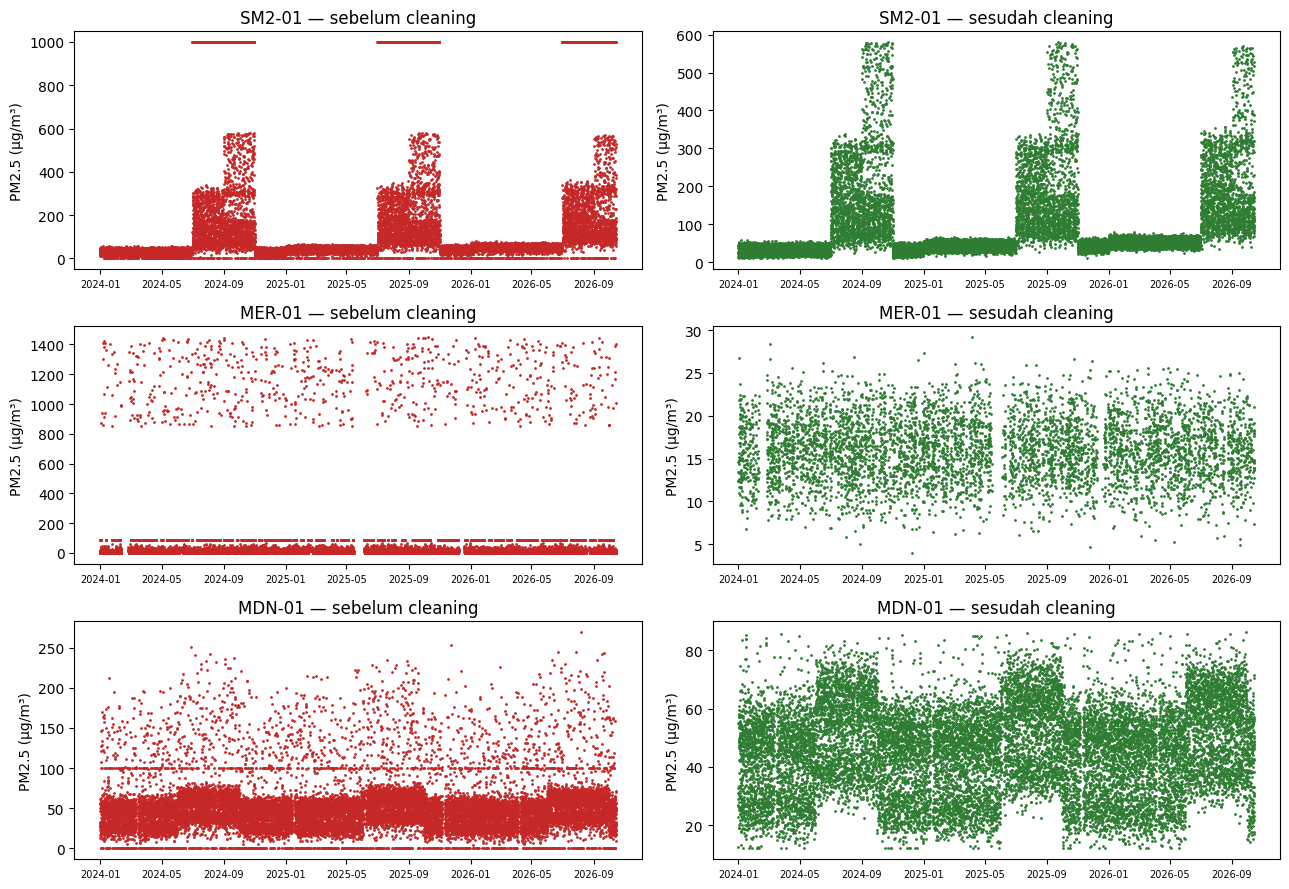

In [8]:
with pd.ExcelWriter(OUT + "02_ringkasan_cleaning.xlsx") as w:
    aturan.to_excel(w, sheet_name="aturan_cleaning", index=False)
    log.to_excel(w, sheet_name="dampak_per_stasiun", index=False)
    log_h.to_frame("nilai").to_excel(w, sheet_name="data_kesehatan")

fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for baris, kode in zip(axes, ["SM2-01", "MER-01", "MDN-01"]):
    m = mentah_simpan[kode]
    t = pd.to_datetime(m["timestamp_start"], format="mixed")
    baris[0].scatter(t, m["pm25"], s=1, color="#c62828")
    baris[0].set_title(f"{kode} — sebelum cleaning")
    c = air[air["stasiun"] == kode]
    baris[1].scatter(c["datetime"], c["pm25"], s=1, color="#2e7d32")
    baris[1].set_title(f"{kode} — sesudah cleaning")
    for ax in baris:
        ax.set_ylabel("PM2.5 (µg/m³)")
        ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.savefig(GAMBAR + "02_sebelum_sesudah_cleaning.png", dpi=150)
plt.show()

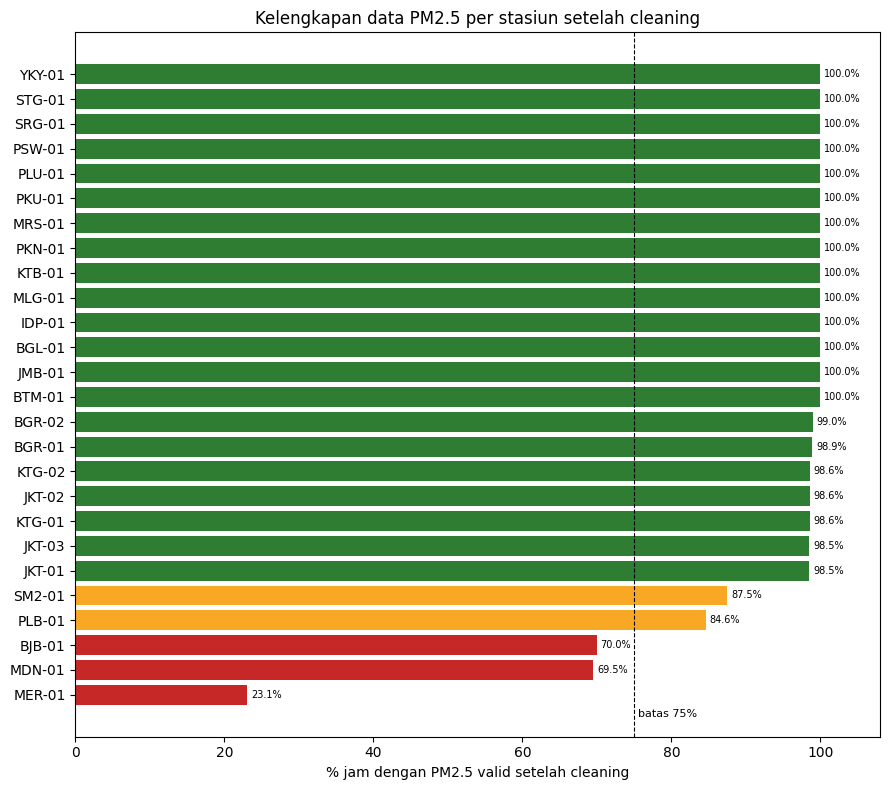

In [9]:
kel = log.dropna(subset=["kelengkapan_pm25_pct"]).sort_values("kelengkapan_pm25_pct")
fig, ax = plt.subplots(figsize=(9, 8))
warna = ["#c62828" if v < 75 else "#f9a825" if v < 95 else "#2e7d32" for v in kel["kelengkapan_pm25_pct"]]
ax.barh(kel["stasiun"], kel["kelengkapan_pm25_pct"], color=warna)
ax.axvline(75, color="black", linestyle="--", linewidth=0.8)
ax.text(75.5, -0.9, "batas 75%", fontsize=8)
for y, v in enumerate(kel["kelengkapan_pm25_pct"]):
    ax.text(v + 0.5, y, f"{v}%", va="center", fontsize=7)
ax.set_xlim(0, 108)
ax.set_xlabel("% jam dengan PM2.5 valid setelah cleaning")
ax.set_title("Kelengkapan data PM2.5 per stasiun setelah cleaning")
plt.tight_layout()
plt.savefig(GAMBAR + "02_kelengkapan_pm25.png", dpi=150)
plt.show()

In [10]:
print(aturan.to_string())
print(log.to_string())
print(log_h.to_string())
print(air.shape, air.columns.tolist())

                          masalah                                                                                                       temuan                                                                              perlakuan
0                   Stasiun rusak                                         JMB-02: status Defective, 99,5% baris error, nilai VALID tidak wajar                                                              Dikeluarkan dari analisis
1   Nilai teks sampah, inf, -9999                                                                  0xDEADBEEF, #VALUE!, ERR_COMM_TIMEOUT, dll.                                                                     Diubah menjadi NaN
2                      Satuan ppm                                                                                       BJB-01, MDN-01, PSW-01                                                 PM ×1000; gas: ppm × BM × 1000 / 24,45
3                  Timestamp 1970                                               